# Aircraft audio: corrected capture-time evidence audit

**James N. Jean IV | Real measurements; anonymized candidates; retrospective corrected rerun.**

The original blind analysis abstained. The subsequent 42-candidate analysis mistakenly used upload time, not capture time. This notebook replaces that cohort with the fresh corrected-capture-time search: 361 selected for refinement, 359 covered under either source model, and 358 ranked for each model/objective. The recording timestamp correction was 920 seconds.

This rerun occurred **after** aircraft identity and approximate recording location were disclosed. The search implementation excludes those values as fitting priors, but this is not a new blind experiment. A-27 is the supplied identity. The original abstention is unchanged.

The notebook reproduces public retained-table views and scalar validation; it does not re-download trajectories or reproduce the private audio search. The companion notebook uses clearly labeled synthetic trajectories.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'data').exists(): ROOT = ROOT.parent
assert (ROOT / 'data/measured_curve.csv').exists(), 'Run from project or notebooks folder'
plt.rcParams.update({'figure.dpi': 125, 'axes.spines.top': False, 'axes.spines.right': False})


## 1. Measured harmonic spacing and the missing interval

The 62 rows are measured common harmonic spacing, not an assumed aircraft engine fundamental. Multiple harmonics can support a spacing estimate; their scatter is not a calibrated measurement-error bar. Two clips cover one event. The approximately 15.16-second unrecorded interval (timing uncertainty about ±1 second) must remain a gap, not zero audio or interpolated evidence.

,elapsed_s,common_spacing_hz,n_harmonics,harmonic_scatter,clip_index
0,10,25.750095,2,0.006342,1
1,12,25.779135,2,0.008266,1
2,14,25.842119,2,0.004966,1
3,16,25.901942,1,NaN,1
4,18,26.017165,3,0.013281,1


,n,start_s,end_s
clip_index,,,
1,30,10,68
2,32,88,158


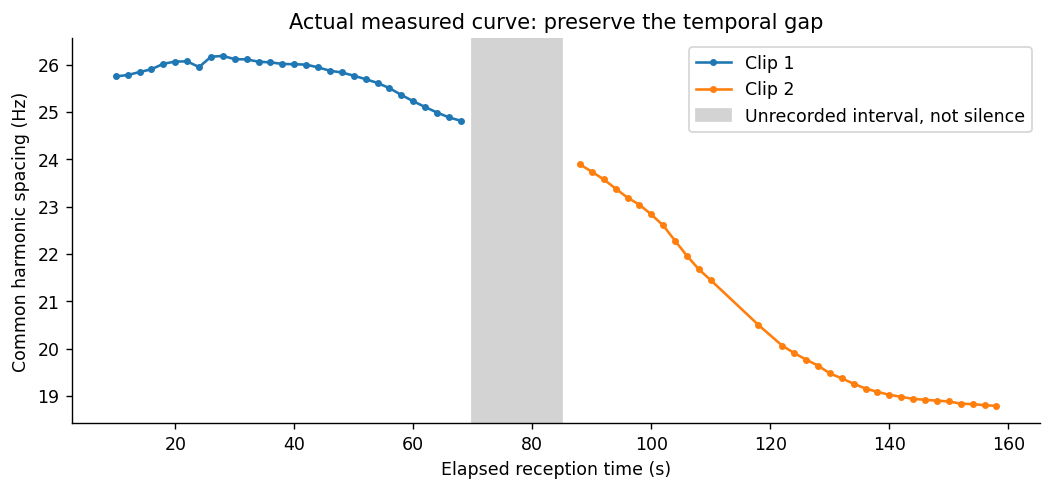

In [2]:
curve = pd.read_csv(ROOT/'data/measured_curve.csv')
assert len(curve)==62
assert curve.elapsed_s.is_monotonic_increasing
display(curve.head())
display(curve.groupby('clip_index').agg(n=('elapsed_s','size'), start_s=('elapsed_s','min'), end_s=('elapsed_s','max')))
fig, ax = plt.subplots(figsize=(10,4))
for clip,q in curve.groupby('clip_index'):
    ax.plot(q.elapsed_s,q.common_spacing_hz,'o-',ms=3,label=f'Clip {clip}')
ax.axvspan(69.84,85,color='lightgray',label='Unrecorded interval, not silence')
ax.set(xlabel='Elapsed reception time (s)',ylabel='Common harmonic spacing (Hz)',title='Actual measured curve: preserve the temporal gap')
ax.legend(); plt.show()

## 2. All 361 corrected-time refinement candidates

Aircraft type is archive metadata, **not an acoustic engine classifier**. Lower ridge RMS is better; higher profiled spectral contrast is better. Missing fits remain missing. Numerical rank is not identification probability, and comparing objectives is not independent replication.

In [3]:
scores=pd.read_csv(ROOT/'data/corrected_candidate_scores.csv')
assert len(scores)==361
display(scores.status.value_counts().to_frame('candidates'))
cols=['label','type','constant_rms_rank','constant_brightness_rank','drift3_rms_rank','drift3_brightness_rank']
display(scores.loc[scores.label.eq('A-27'),cols])
display(scores[cols].sort_values('drift3_rms_rank',na_position='last'))

,candidates
status,
both source models covered,357
no covered retained refinement mode,2
drift model only,1
constant model only,1


,label,type,constant_rms_rank,constant_brightness_rank,drift3_rms_rank,drift3_brightness_rank
187,A-27,P28A,1.0,2.0,1.0,5.0


,label,type,constant_rms_rank,constant_brightness_rank,drift3_rms_rank,drift3_brightness_rank
187,A-27,P28A,1.0,2.0,1.0,5.0
293,C-294,EC30,4.0,7.0,2.0,2.0
35,C-036,C172,2.0,3.0,3.0,6.0
156,C-157,P28A,3.0,4.0,4.0,10.0
232,C-233,E75L,11.0,6.0,5.0,8.0
...,...,...,...,...,...,...
119,C-120,B738,357.0,347.0,357.0,343.0
112,C-113,B763,358.0,358.0,358.0,350.0
126,C-127,A321,NaN,NaN,NaN,NaN
279,C-280,PC12,NaN,NaN,NaN,NaN


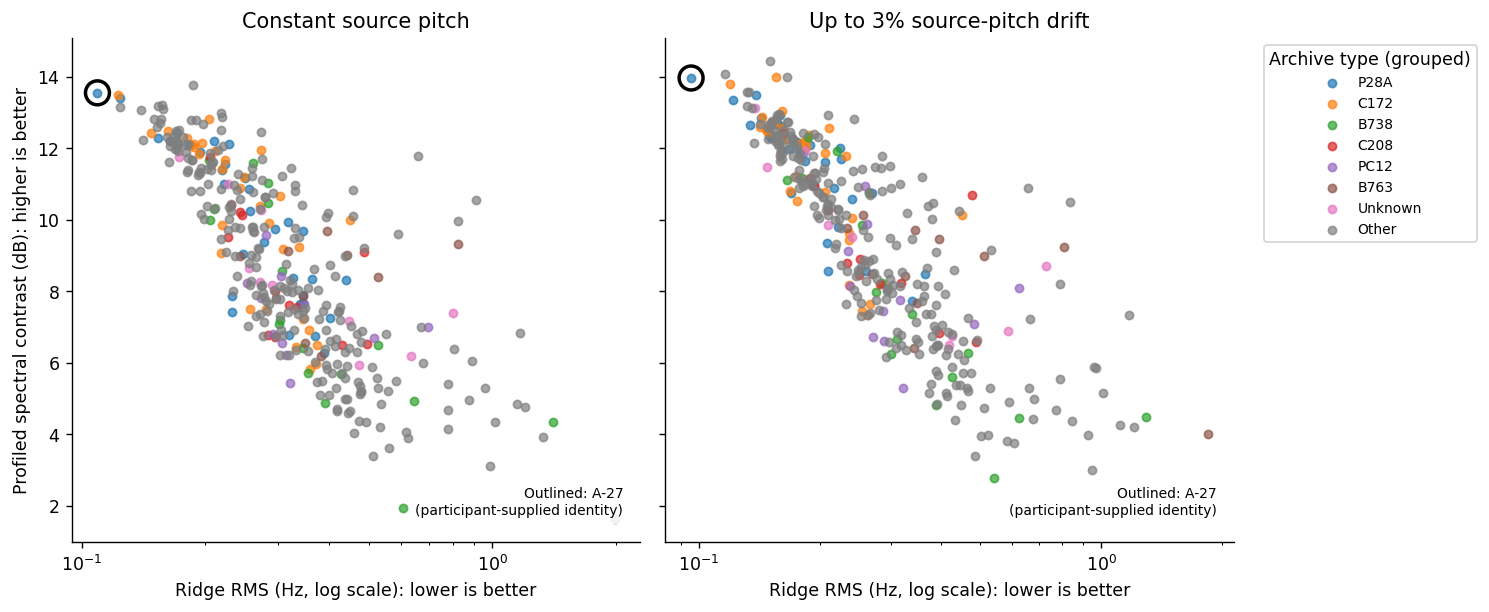

In [4]:
top_types=scores.loc[scores.type.ne('Unknown'),'type'].value_counts().head(6).index.tolist()
group=scores.type.where(scores.type.isin(top_types+['Unknown']),'Other')
groups=top_types+['Unknown','Other']
palette={g:plt.get_cmap('tab10')(i) for i,g in enumerate(groups)}
fig,axes=plt.subplots(1,2,figsize=(12,5),sharey=True)
for ax,prefix,title in zip(axes,['constant','drift3'],['Constant source pitch','Up to 3% source-pitch drift']):
    for typ in groups:
        q=scores[group.eq(typ)]
        ax.scatter(q[prefix+'_rms_score'],q[prefix+'_brightness_score'],color=palette[typ],label=typ,s=22,alpha=.7)
    target=scores[scores.label.eq('A-27')].iloc[0]
    ax.scatter(target[prefix+'_rms_score'],target[prefix+'_brightness_score'],s=190,facecolors='none',edgecolors='black',linewidths=2)
    ax.text(.97,.05,'Outlined: A-27\n(participant-supplied identity)',transform=ax.transAxes,ha='right',va='bottom',fontsize=8,bbox=dict(facecolor='white',alpha=.9,edgecolor='none'))
    ax.set_xscale('log')
    ax.set(title=title,xlabel='Ridge RMS (Hz, log scale): lower is better')
axes[0].set_ylabel('Profiled spectral contrast (dB): higher is better')
axes[1].legend(title='Archive type (grouped)',bbox_to_anchor=(1.04,1),fontsize=8)
plt.tight_layout();plt.show()

## 3. Corrected search coverage and ranking

The table includes the union of candidates retained by the documented coarse ranking rule, not every aircraft in the archive. Missing fits are not negative evidence. Spectral ranks are among retained ridge-screened geometry modes, not an independent exhaustive spectral search. Lower ridge RMS and higher spectral contrast are better; neither is a probability.

The 42-candidate upload-time cohort is historical and is **not** the corrected recording-time cohort.

In [5]:
import json
summary=json.loads((ROOT/'data/corrected_search_summary.json').read_text())
display(pd.Series({k:summary[k] for k in ['archive_files','coarse_aircraft','coarse_covered_aircraft','selected_for_refinement','refined_covered_aircraft']}))
display(pd.DataFrame(summary['target_scores']).T)
assert scores.constant_rms_rank.notna().sum()==358
assert scores.drift3_rms_rank.notna().sum()==358
print(summary['refinement_rule'])
print(summary['pixel_scope'])

archive_files               75222
coarse_aircraft              6743
coarse_covered_aircraft      3880
selected_for_refinement       361
refined_covered_aircraft      359
dtype: int64

,rank,rms_hz,profiled_brightness_db
0|rms_hz,1.0,0.109325,13.413069
0|profiled_brightness_db,2.0,0.111567,13.551919
0.03|rms_hz,1.0,0.095596,13.906659
0.03|profiled_brightness_db,5.0,0.095811,13.966583


Union of top200aircraft for each of two source models and two coarse objectives, not an identity/location filter
Ranking among retained ridge-screened geometry modes, not independent exhaustive pixel optimization


## 4. Post-freeze comparison with the approximate reference

The inferred points were frozen before the comparison calculation. The participant's approximate recording location is withheld from this public package. Only scalar separation errors are shown: no coordinates, bearings, or map. These distances are **not** confidence radii and reference precision is limited.

The search happened after disclosure, although identity/location were excluded from fitting inputs. A strong retrospective agreement is not a blind-identification claim. Alternative spatial solutions remain plausible; there is no calibrated 95% region or unique observer pin.

,source_model,objective,rank,ranked_candidates,distance_to_reference_m,rms_hz
0,constant,curve_rms,1,358,56.5016,0.1093
1,bounded_3pct_drift,curve_rms,1,358,79.0624,0.0956
2,constant,spectral_contrast,2,358,167.5713,0.1116
3,bounded_3pct_drift,spectral_contrast,5,358,158.6436,0.0958


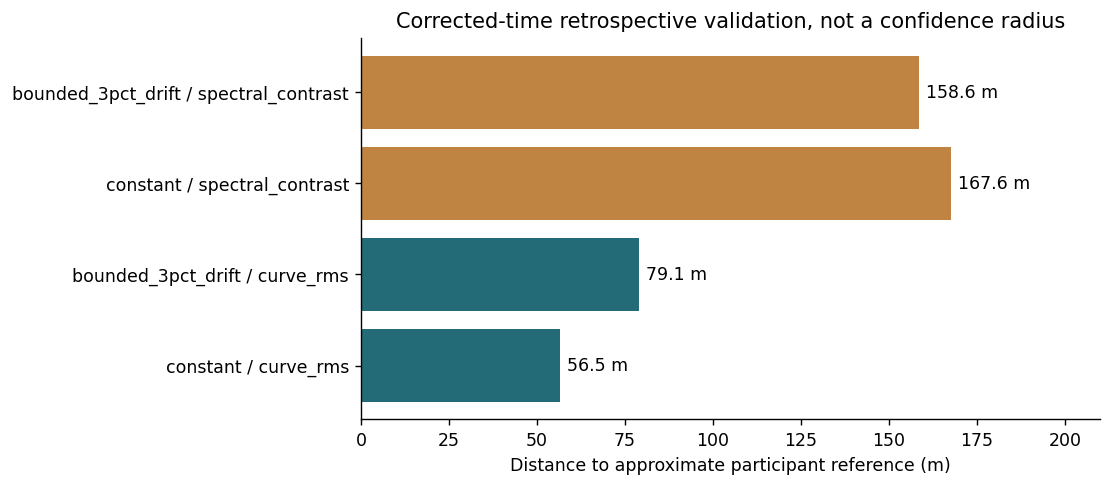

In [6]:
validation=pd.read_csv(ROOT/'data/corrected_location_validation.csv')
display(validation.round(4))
fig,ax=plt.subplots(figsize=(9,4))
labels=validation.source_model+' / '+validation.objective
bars=ax.barh(labels,validation.distance_to_reference_m,color=['#246b78','#246b78','#c08442','#c08442'])
ax.bar_label(bars,fmt='%.1f m',padding=4)
ax.set(xlabel='Distance to approximate participant reference (m)',title='Corrected-time retrospective validation, not a confidence radius',xlim=(0,210))
plt.tight_layout();plt.show()

## Conclusions and next experiment

A-27 ranks first of 358 by curve RMS under both source models, but second and fifth by the spectral objectives. Its curve-optimal inferred points are approximately 56.5 m and 79.1 m from the participant reference. This is a promising **post-disclosure, corrected-time** result, not proof of unique identity or a general accuracy guarantee.

The private diagnostics also retain an alternative near-optimal spatial basin roughly 2.5 km away. A preregistered blind test with independent recordings, measured clock accuracy and withheld reference coordinates is needed next. Public tables reproduce these displays; full trajectory/environment fitting requires the private archived inputs.